# Accuracy of PyToF — quick checks

This notebook runs in about a minute and answers the questions a user has: *how accurate are the results of PyToF, and how do I know?* It compares PyToF with exact solutions and independent literature results:

1. a **summary** of the error tables that `ToF.get_Js_errors()` uses,
2. the **normalized moment of inertia** of spheres with analytical solutions,
3. **Love functions** of three density profiles with analytical solutions (Gavrilov et al. 1976),
4. **gravitational moments** of the Jupiter polytrope against the Bessel-function solution of Wisdom & Hubbard (2016), as a function of grid size and order,
5. **differential rotation** against the independent CMS method (Wisdom & Hubbard 2016),
6. a **reproducibility check** of the shipped error tables.

The full study — all orders up to $N = 2^{15}$, all binnings, the comparison with the code of Movshovitz & Fortney (2022), the second wind profile, and the code that regenerates the error tables — is in [`accuracy_full.ipynb`](accuracy_full.ipynb) (takes tens of minutes). The reference numbers and their citations are in [`references.py`](references.py); the shared code is in [`helpers.py`](helpers.py). The test suite (`tests/`) uses the same reference values.

In [1]:
import sys
import pathlib
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

# Optional personal matplotlib style: used if a file mpl_config.py exists in a
# folder above this one, silently ignored otherwise.
for parent in pathlib.Path.cwd().resolve().parents[:4]:
    if (parent / "mpl_config.py").exists():
        sys.path.insert(0, str(parent))
        break
try:
    from mpl_config import apply_mpl_opts

    apply_mpl_opts()
except ImportError:
    pass  # plain matplotlib defaults

import helpers
import references
from PyToF import ToF

PYTOF_DIR = pathlib.Path(helpers.ROOT) / "PyToF"

## 1 · Summary: how accurate are the gravitational moments?

PyToF ships tables of the relative error of $J_2, J_4, \ldots$ as a function of the order, the number of grid points $N$ and the binning; they come from the Jupiter polytrope against the exact solution (section 4, and `accuracy_full.ipynb` for how they are made). `get_Js_errors()` looks up the entry for the current settings. Here are the tables for Simpson's rule without binning (`n_bin = N`), which is the default:

In [2]:
tables = np.load(PYTOF_DIR / "accuracy_data_simpson.npz")
Ns_n_bins = tables["Ns_n_bins"]
n_js = {"04": 4, "07": 7, "10": 10}

def table_row(key, N):
    i = int(np.flatnonzero((Ns_n_bins[:, 0] == N) & (Ns_n_bins[:, 1] == N))[0])
    n_steps = len(Ns_n_bins) // len(np.unique(Ns_n_bins[:, 0]))
    # layout of the tables: [N index, J index, binning index]; the first binning (N/n_bin = 1) of this N
    return tables[f"rel_error_{key}"][i // n_steps, :, i % n_steps]

print("relative error of J_2n (Simpson, no binning)")
print(f"{'order':>5s}{'N':>7s}" + "".join(f"{'J_' + str(2 * n):>10s}" for n in (1, 2, 3, 4, 5, 6, 8, 10)))
for key, order in (("04", 4), ("07", 7), ("10", 10)):
    for N in (256, 1024, 4096, 16384):
        row = table_row(key, N)
        cells = [f"{row[n - 1]:10.1e}" if n <= order else f"{'':>10s}" for n in (1, 2, 3, 4, 5, 6, 8, 10)]
        print(f"{order:5d}{N:7d}" + "".join(cells))

relative error of J_2n (Simpson, no binning)
order      N       J_2       J_4       J_6       J_8      J_10      J_12      J_16      J_20
    4    256   1.7e-05   2.5e-04   8.7e-03   8.7e-02                                        
    4   1024   5.1e-06   2.5e-04   8.7e-03   8.7e-02                                        
    4   4096   4.3e-06   2.5e-04   8.7e-03   8.7e-02                                        
    4  16384   4.3e-06   2.5e-04   8.7e-03   8.7e-02                                        
    7    256   1.3e-05   7.6e-06   3.3e-06   8.5e-05   1.7e-03   2.5e-02                    
    7   1024   8.3e-07   6.3e-07   2.9e-06   9.5e-05   1.7e-03   2.5e-02                    
    7   4096   5.2e-08   1.1e-07   3.0e-06   9.5e-05   1.7e-03   2.5e-02                    
    7  16384   2.4e-09   8.5e-08   1.9e-06   1.3e-04   1.6e-03   2.5e-02                    
   10    256   1.3e-05   7.5e-06   2.8e-07   9.7e-06   1.9e-05   6.0e-05   5.5e-03   2.1e-01
   10   1024   8.4e-07   

**How to read it.** The tables are for the polytrope (solid body rotation) and show the two limits of Notebook 1 of the tutorial:

* *order 4*: $J_2$ to $\sim5\times10^{-6}$, $J_4$ to $\sim3\times10^{-4}$, $J_6$ and $J_8$ only to 1% and 10%, however large $N$ is;
* *order 7*: $J_2$ to $J_6$ to better than $10^{-5}$ (for $N\ge1024$), $J_8$ to $10^{-4}$, $J_{10}$ to $2\times10^{-3}$, $J_{12}$ and above not usable;
* *order 10*: $J_2$ to $J_8$ to $10^{-7}$ or better (large $N$), up to $J_{12}$ better than $2\times10^{-5}$, $J_{16}$ at 0.5%, and $J_{20}$ is not reliable at all (20%).

For a typical giant-planet interior model, in which $J_2$ to $J_6$ matter and have measurement errors that are relative $10^{-5}$ to $10^{-2}$, order 7 with a few thousand points is usually enough.

## 2 · Normalized moment of inertia

Three bodies with exact results: a sphere of constant density ($I/(MR^2) = 2/5$), a sphere with density decreasing linearly from the centre to zero at the surface ($4/15$), and a rotating spheroid of constant density (a Maclaurin spheroid) for which the moment of inertia scales with the squared equatorial radius, $I/(M l_\mathrm{max}^2) = \frac{2}{5}\,(R_\mathrm{eq}/R_\mathrm{m})^2$:

In [3]:
N = 2**10
radius = 1e6
radii = radius * np.linspace(1, 1e-3, N)
cases = [
    ("constant density sphere", 1000 * np.ones(N), np.inf, references.NMOI_SPHERE_CONSTANT_DENSITY),
    ("linear density sphere", np.linspace(0, 1000, N), np.inf, references.NMOI_SPHERE_LINEAR_DENSITY),
    ("rotating constant-density spheroid", 1000 * np.ones(N), 24 * 3600, None),
]

print(f"{'':36s}{'PyToF':>10s}{'exact':>10s}{'rel. diff.':>12s}")
for name, dens, period, exact in cases:
    mass = -4 * np.pi * trapezoid(dens * radii**2, radii)
    X = ToF(N=N, M_phys=mass, R_phys=[radius, "mean"], Period=period, R_ref=radius)
    X.li, X.rhoi = radii, dens
    X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)
    X.relax_to_shape()
    if exact is None:
        exact = 2 / 5 * X.R_eq_to_R_m**2
    nmoi = X.get_NMoI()
    print(f"{name:36s}{nmoi:10.6f}{exact:10.6f}{abs(nmoi / exact - 1):12.1e}")

                                         PyToF     exact  rel. diff.
constant density sphere               0.400000  0.400000     1.0e-09
linear density sphere                 0.266667  0.266667     4.0e-09


rotating constant-density spheroid    0.406468  0.406468     8.5e-10


## 3 · Love functions

The three density profiles of Gavrilov, Zharkov and Leontev (1976) — linear, quadratic and polytropic — have analytical (or rapidly converging series) solutions for the density, gravity $g$, the perturbation function $T_n(r)$ and the Love function $K_n(r)$ (implemented in `references.love_cases`). Solid curves: PyToF; black dotted: analytical. Each column shows one profile, the colored lines are the degrees $n = 2 \ldots 7$:

largest absolute deviation of K_n (r/R)^n from the analytical function, n = 2 ... 7:
  linear      8.5e-07  4.6e-07  4.0e-07  3.5e-07  3.1e-07  2.8e-07
  quadratic   2.0e-06  1.2e-06  9.3e-07  7.7e-07  6.6e-07  5.8e-07
  polytropic  2.7e-06  8.2e-07  4.1e-07  2.6e-07  1.8e-07  1.3e-07


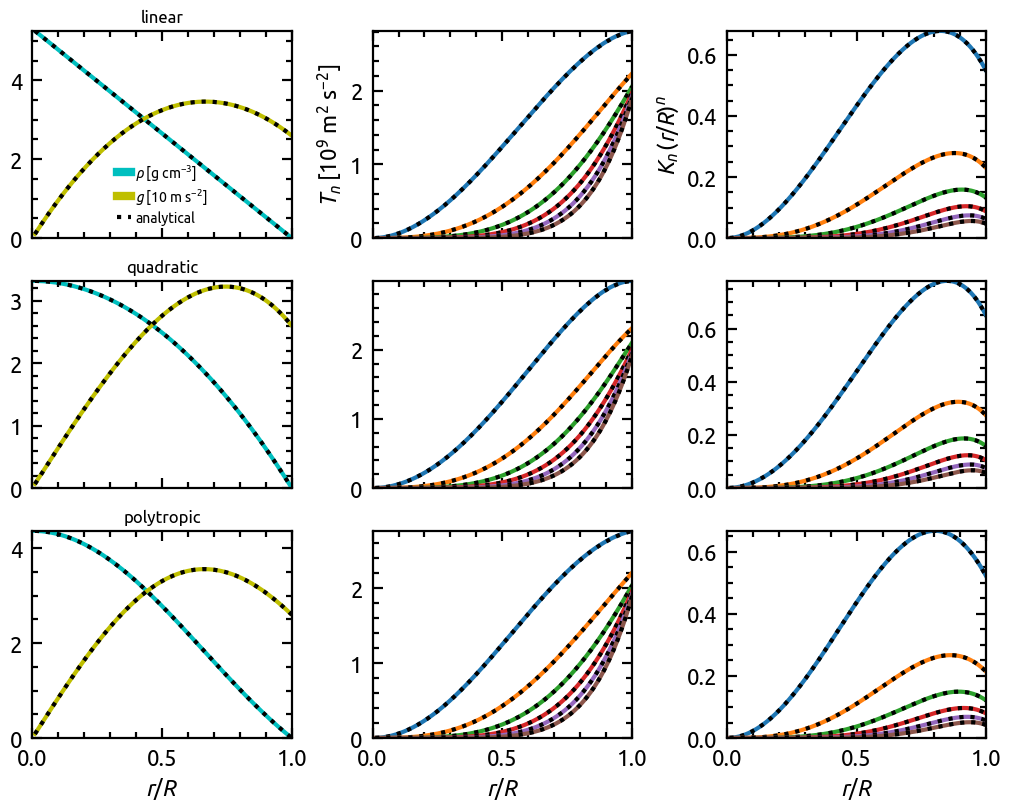

In [4]:
N = 2**10
rho_mean = 1326.0  # kg/m^3
radius = 70e6  # m
G = 6.6738480e-11
cases = references.love_cases(rho_mean, radius, G)

fig, axs = plt.subplots(3, 3, figsize=(10, 8), layout="constrained", sharex=True)
deviations = {}
for i, (name, case) in enumerate(cases.items()):
    radii = radius * np.linspace(0.01, 1, N)
    mass = 4 * np.pi * trapezoid(case["rho"](radii) * radii**2, radii)
    X = ToF(N=N, M_phys=mass, R_phys=[radius, "mean"], Period=np.inf, G=G, R_ref=radius)
    X.li, X.rhoi = radii[::-1], case["rho"](radii[::-1])
    X.m_rot_calc = 0.0
    X.relax_to_shape()

    for n in range(2, 8):
        r, T_n, K_n = X.get_Kn(n)
        axs[i, 1].plot(r / radius, T_n / 1e9)
        axs[i, 1].plot(radii / radius, case["T"](radii, n) / 1e9, "k:")
        axs[i, 2].plot(r / radius, K_n * (r / radius) ** n)
        axs[i, 2].plot(radii / radius, case["K"](radii, n), "k:")
        deviations[name, n] = np.nanmax(np.abs(K_n * (r / radius) ** n - case["K"](r, n)))

    # (after get_Kn: it makes sure X.U, the potential, is up to date)
    axs[i, 0].plot(X.li / radius, X.rhoi / 1000, color="c")
    axs[i, 0].plot(X.li / radius, np.gradient(X.U, X.li) / 10, color="y")
    axs[i, 0].plot(radii / radius, case["rho"](radii) / 1000, "k:")
    axs[i, 0].plot(radii / radius, case["g"](radii) / 10, "k:")
    axs[i, 0].set_title(name, fontsize=12)

axs[0, 0].legend(
    [plt.Line2D([], [], color="c", lw=6), plt.Line2D([], [], color="y", lw=6), plt.Line2D([], [], color="k", ls=":")],
    [r"$\rho$ [g cm$^{-3}$]", r"$g$ [10 m s$^{-2}$]", "analytical"],
    frameon=False, fontsize=10, loc="lower center",
)
axs[0, 1].set_ylabel(r"$T_n$ [$10^9$ m$^2$ s$^{-2}$]")
axs[0, 2].set_ylabel(r"$K_n\,(r/R)^n$")
for ax in axs[2]:
    ax.set_xlabel(r"$r/R$")
    ax.set_xlim(0, 1)

print(f"largest absolute deviation of K_n (r/R)^n from the analytical function, n = 2 ... 7:")
for name in cases:
    print(f"  {name:11s}", "  ".join(f"{deviations[name, n]:.1e}" for n in range(2, 8)))

The curves lie on top of each other; the deviation of the Love function is of order $10^{-6}$ for $N = 1024$. (The functions $T_n$ agree to about $10^{-3}$ in relative terms; for this reason the Love number, not $T_n$, is the quantity to rely on.)

## 4 · Gravitational moments against the exact solution

The Wisdom & Hubbard (2016) Jupiter polytrope ($\rho = \sqrt{P}$, solid body rotation with $m = 0.089195487$) has an exact solution in terms of Bessel functions. We run PyToF for $N = 2^5 \ldots 2^{12}$ and the three orders, in parallel. Each curve is one order; the error first falls with $N$ and then flattens at the floor of the order. The lower right panel gives the run time per iteration:

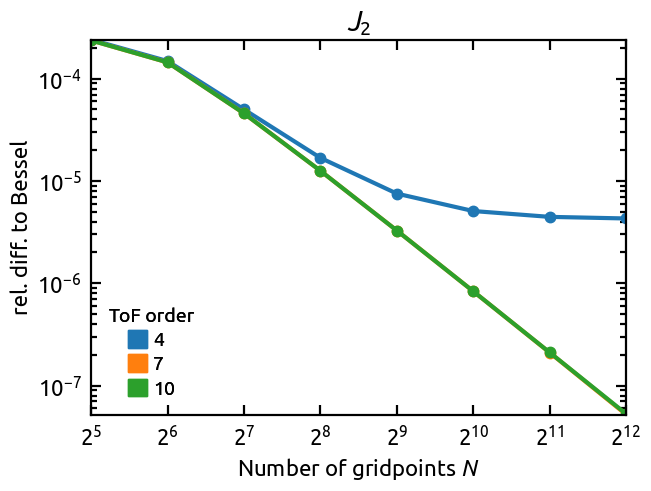

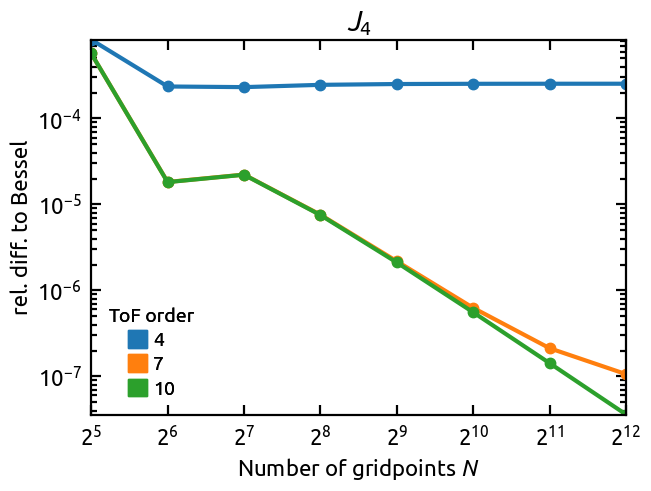

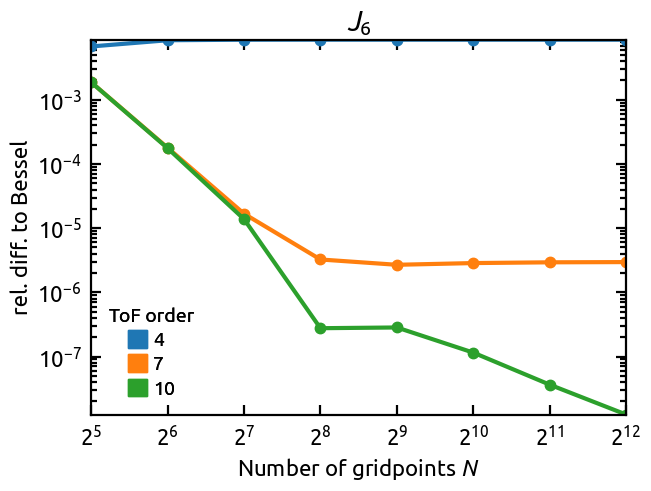

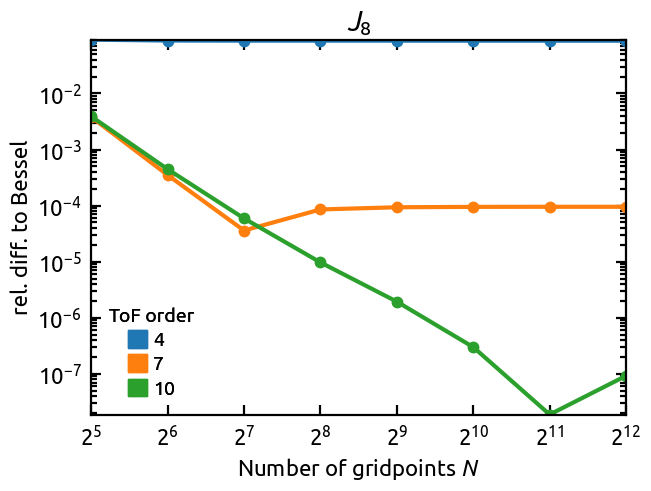

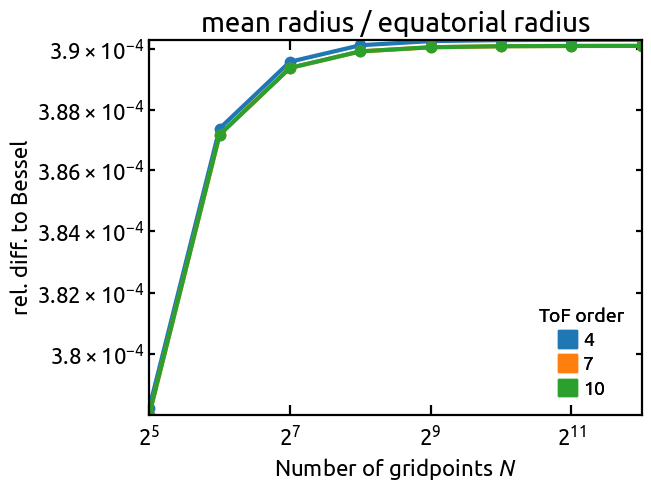

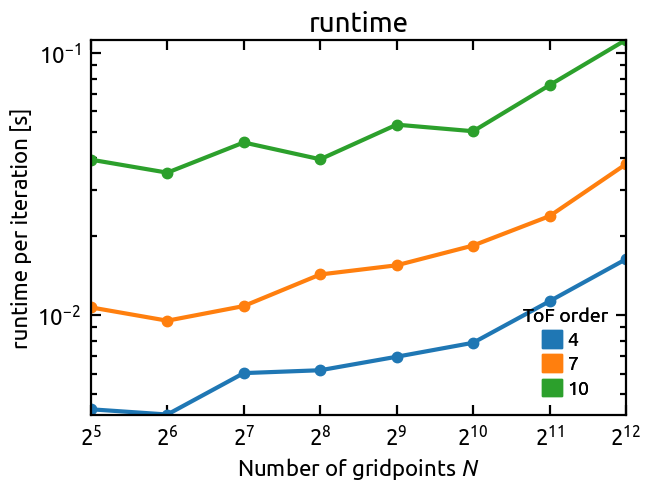

In [5]:
Ns = 2 ** np.arange(5, 13)
sweep = helpers.sweep_pytof(Ns, steps=(1,), progress=False)
figs = helpers.plot_convergence(Ns, references.Bessel, "Bessel", sweep, which=[1, 2, 3, 4, 0, 11])

**The mean radius.** The panel for `mean radius / equatorial radius` ($R_\mathrm{eq}/R_\mathrm{m}$) shows a difference of $4\times10^{-4}$ to the Bessel solution that does not depend on the grid or the order, while the moments converge. This is an open question (a different definition of the mean radius, or a real discrepancy); it does not affect the moments, but be careful with the *shape* at this level.

## 5 · Differential rotation

With barotropic differential rotation (`alphas`) there is no exact solution. Wisdom & Hubbard (2016) give results of the CMS method for the wind profile "DR2" (`references.CMSDR2`), an independent method that converges differently. PyToF agrees with it, here for $N=2048$:

In [6]:
alphas = references.alphas_array(references.ALPHAS_DR2)
print(f"{'order':>5s}" + "".join(f"{'J_' + str(2 * n):>10s}" for n in range(1, 7)) + "   rel. difference to CMS")
for order in (4, 7, 10):
    t, res, it = helpers.run_pytof(2048, 2048, order, alphas=alphas)
    diff = np.abs(res[1:7] / references.CMSDR2[1:7] - 1) if order > 4 else np.abs(res[1:5] / references.CMSDR2[1:5] - 1)
    print(f"{order:5d}" + "".join(f"{x:10.1e}" for x in diff))

order       J_2       J_4       J_6       J_8      J_10      J_12   rel. difference to CMS
    4   5.3e-05   1.6e-04   1.1e-02   8.6e-02


    7   5.3e-05   9.7e-05   1.3e-04   3.9e-04   2.3e-03   3.5e-02


   10   5.3e-05   9.7e-05   1.3e-04   1.5e-04   7.9e-05   1.3e-04


For order 4 only $J_2$ to $J_8$ are computed. Up to $J_6$ all orders agree with the CMS values to $\sim10^{-4}$ (the $5\times10^{-5}$ in $J_2$ is the same for all three orders, i.e. not a truncation effect of PyToF; this notebook does not resolve whether it stems from the CMS reference or from PyToF), and order 10 stays within $1.3\times10^{-4}$ up to $J_{12}$. The 4th and 7th order results lose accuracy for the higher moments exactly as in the solid body case of section 4. The winds change the moments by far more than these differences (notebook 4 of the tutorial); `accuracy_full.ipynb` repeats the comparison for all $N$ and a second wind profile.

## 6 · The shipped error tables are reproducible

The tables of section 1 are data files in the package. To make sure they can be regenerated with the code that is distributed with them, we recompute a handful of entries, chosen across $N$, binning and order, and compare:

In [7]:
Ns_all = 2 ** np.linspace(3, 15, 13)
steps_all = 2 ** np.arange(int(np.log2(Ns_all[-2])))
checks = [(5, 0), (7, 0), (7, 3), (8, 2), (9, 4)]  # (N index, binning index)

worst = 0.0
for iN, js in checks:
    N, step = int(Ns_all[iN]), steps_all[js]
    for order, key in ((4, "04"), (7, "07"), (10, "10")):
        t, res, it = helpers.run_pytof(N, int(N / step), order)
        new = np.abs((res[1:] - references.Bessel[1 : order + 1]) / res[1:])
        old = tables[f"rel_error_{key}"][iN, :, js]
        worst = max(worst, np.max(np.abs(new / old - 1)))
print(f"largest relative deviation between recomputed and shipped table entries: {worst:.1e}")

largest relative deviation between recomputed and shipped table entries: 0.0e+00


A value of $0$ (or of rounding size) means the tables belong to this version of the code. If you change anything in the numerics, regenerate them with `python accuracy/helpers.py --write-accuracy-data` (or in `accuracy_full.ipynb`).